# 14 – Residual TFT + EWC against the conventional baselines (D23 results)

This notebook only **reads** the committed results files; it trains nothing and runs in seconds.

- **Sources:** `results/forecasting_d23_e1.json` (E1, horizons 1–3) and `results/forecasting_d23_e2.json` (E2, horizons 1–6), pre-registered as D23 in `docs/DECISIONS.md`. Data: S6 (Wheeler et al. 2025), seven test cases streamed as continual-learning tasks.
- **Metric:** final average test RMSE in percentage points (pp) of SOH, where SOH is relative to the first observed RPT capacity of each cell (not nominal capacity). Forgetting in pp.
- **Runs:** 10 task orders × 5 seeds per seed set; *main* = seeds 0–4, *replicate* = seeds 5–9. Deterministic or fitted-once baselines have a single value.
- **Tests:** paired two-sided Wilcoxon against the reference (residual TFT + EWC), Holm-corrected within each seed set. `diff` = reference − other (negative = TFT + EWC has lower error).
- **D21 replication rule:** a difference is a finding only if p_Holm < 0.05 in both seed sets, with the same sign and |diff| ≥ 0.05 pp in both; |diff| < 0.05 pp in both is practically equivalent; anything else is not replicated.
- Tables and verdicts come from the same code that builds the paper tables (`scripts/make_d24_outputs.py`), so they match the manuscript.
- **D24 (RC-TFT and the literature baselines) is in notebook 15** (`15_d24_results.ipynb`), from the completed run of 13–14 Oct 2026.

In [1]:
import importlib.util
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "scripts" / "make_d24_outputs.py").is_file())
spec = importlib.util.spec_from_file_location("d24_outputs", REPO_ROOT / "scripts" / "make_d24_outputs.py")
O = importlib.util.module_from_spec(spec)
spec.loader.exec_module(O)          # imports only; its main() (which writes files) is not called
%matplotlib inline

REF = "tft_residual_ewc"
data = {}
for exp in ("e1", "e2"):
    path = REPO_ROOT / "results" / f"forecasting_d23_{exp}.json"
    data[exp] = pd.read_json(path, typ="series").to_dict()
    env = data[exp]["environment"]
    print(f"{exp}: {path.name}, decision {data[exp]['decision']}, profile {data[exp]['profile']}, "
          f"horizons {data[exp]['horizons']}, {data[exp]['n_samples']} samples, commit {env['git_commit'][:7]}, "
          f"git_dirty={env['git_dirty']}")
print("kernel: Python", sys.version.split()[0], "| results environment:",
      {k: v for k, v in env.items() if k not in ("git_commit", "git_dirty")})

e1: forecasting_d23_e1.json, decision D23, profile paper, horizons [1, 2, 3], 2409 samples, commit 5ae2f84, git_dirty=False
e2: forecasting_d23_e2.json, decision D23, profile paper, horizons [1, 2, 3, 4, 5, 6], 4638 samples, commit 5ae2f84, git_dirty=False
kernel: Python 3.11.15 | results environment: {'python': '3.11.15', 'numpy': '2.4.6', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'torch': '2.14.1+cpu'}


## 1. Final test RMSE of every method

In [2]:
def comparison_view(exp):
    c = O.comparison(data[exp])
    view = c[["label", "kind", "rmse_main_mean", "rmse_main_sd", "rmse_replicate_mean", "rmse_replicate_sd",
              "forgetting_main"]].rename(columns={
        "label": "method", "rmse_main_mean": "RMSE main (pp)", "rmse_main_sd": "s.d. main",
        "rmse_replicate_mean": "RMSE replicate (pp)", "rmse_replicate_sd": "s.d. replicate",
        "forgetting_main": "forgetting main (pp)"})
    return c, view

comp = {}
for exp in ("e1", "e2"):
    comp[exp], view = comparison_view(exp)
    print(f"{exp.upper()} (horizons {data[exp]['horizons']}), sorted by main RMSE")
    display(view.round(3))

E1 (horizons [1, 2, 3]), sorted by main RMSE


,method,kind,RMSE main (pp),s.d. main,RMSE replicate (pp),s.d. replicate,forgetting main (pp)
0,"TFT + EWC, residual",continual (stream),0.339,0.164,0.314,0.067,0.100
1,Linear extrapolation,deterministic,0.343,NaN,0.343,NaN,NaN
2,"TFT fine-tuning, residual",continual (stream),0.347,0.121,0.337,0.110,0.103
3,"MLP + EWC, residual",continual (stream),0.374,0.056,0.366,0.071,0.053
4,"MLP fine-tuning, residual",continual (stream),0.405,0.082,0.403,0.084,0.082
5,"MLP fine-tuning, direct",continual (stream),0.413,0.133,0.351,0.106,0.207
6,"TFT fine-tuning, direct",continual (stream),0.424,0.191,0.444,0.207,0.151
7,Gradient boosting,fitted once on all tasks,0.451,NaN,0.451,NaN,NaN
8,"TFT + EWC, direct",continual (stream),0.504,0.206,0.487,0.213,0.228
9,"MLP + EWC, direct",continual (stream),0.519,0.286,0.527,0.239,0.216


E2 (horizons [1, 2, 3, 4, 5, 6]), sorted by main RMSE


,method,kind,RMSE main (pp),s.d. main,RMSE replicate (pp),s.d. replicate,forgetting main (pp)
0,Linear extrapolation,deterministic,0.485,NaN,0.485,NaN,NaN
1,"TFT + EWC, residual",continual (stream),0.561,0.152,0.534,0.124,0.093
2,"MLP fine-tuning, residual",continual (stream),0.656,0.202,0.695,0.213,0.201
3,"TFT fine-tuning, direct",continual (stream),0.658,0.400,0.694,0.418,0.307
4,"MLP + EWC, residual",continual (stream),0.659,0.208,0.694,0.217,0.205
5,"TFT fine-tuning, residual",continual (stream),0.673,0.270,0.612,0.229,0.282
6,"MLP fine-tuning, direct",continual (stream),0.781,0.307,0.775,0.268,0.414
7,"TFT + EWC, direct",continual (stream),0.802,0.281,0.835,0.309,0.135
8,Gradient boosting,fitted once on all tasks,0.898,NaN,0.898,NaN,NaN
9,"MLP + EWC, direct",continual (stream),1.004,0.447,0.996,0.583,0.385


## 2. Paired tests against residual TFT + EWC, with the replication verdict

In [3]:
tests = {}
for exp in ("e1", "e2"):
    t = O.tests_table(data[exp])
    tests[exp] = t
    print(f"{exp.upper()}: reference = {t['reference'].iloc[0]}")
    display(t[["metric", "other", "diff_main", "p_holm_main", "diff_replicate", "p_holm_replicate", "verdict"]]
            .round({"diff_main": 3, "diff_replicate": 3}).style.format({"p_holm_main": "{:.2g}", "p_holm_replicate": "{:.2g}"}))

E1: reference = TFT + EWC, residual


,metric,other,diff_main,p_holm_main,diff_replicate,p_holm_replicate,verdict
0,final_avg_error,"MLP + EWC, direct",-0.180000,0.0069,-0.213000,5.8e-07,"replicated, reference better"
1,forgetting,"MLP + EWC, direct",-0.116000,0.054,-0.132000,0.0032,not replicated
2,backward_transfer,"MLP + EWC, direct",-0.129000,0.027,-0.125000,0.0087,"replicated, reference better"
3,final_avg_error,"MLP fine-tuning, direct",-0.074000,0.014,-0.037000,0.87,not replicated
4,forgetting,"MLP fine-tuning, direct",-0.107000,0.00051,-0.078000,0.0032,"replicated, reference better"
5,backward_transfer,"MLP fine-tuning, direct",-0.117000,0.00024,-0.063000,0.097,not replicated
6,final_avg_error,"MLP + EWC, residual",-0.035000,0.002,-0.052000,0.00034,not replicated
7,forgetting,"MLP + EWC, residual",0.046000,0.22,0.021000,0.87,practically equivalent
8,backward_transfer,"MLP + EWC, residual",0.004000,1,-0.007000,1,practically equivalent
9,final_avg_error,"MLP fine-tuning, residual",-0.066000,0.00097,-0.089000,6.2e-07,"replicated, reference better"


E2: reference = TFT + EWC, residual

,metric,other,diff_main,p_holm_main,diff_replicate,p_holm_replicate,verdict
0,final_avg_error,"MLP + EWC, direct",-0.443000,1.4e-11,-0.462000,1.3e-06,"replicated, reference better"
1,forgetting,"MLP + EWC, direct",-0.292000,4.9e-08,-0.327000,1.9e-05,"replicated, reference better"
2,backward_transfer,"MLP + EWC, direct",-0.266000,0.00013,-0.282000,0.0022,"replicated, reference better"
3,final_avg_error,"MLP fine-tuning, direct",-0.220000,6.5e-05,-0.241000,1.4e-06,"replicated, reference better"
4,forgetting,"MLP fine-tuning, direct",-0.321000,8.1e-08,-0.315000,4.3e-07,"replicated, reference better"
5,backward_transfer,"MLP fine-tuning, direct",-0.272000,9.3e-06,-0.269000,9.6e-07,"replicated, reference better"
6,final_avg_error,"MLP + EWC, residual",-0.098000,0.096,-0.160000,9.4e-07,not replicated
7,forgetting,"MLP + EWC, residual",-0.112000,0.013,-0.139000,0.00023,"replicated, reference better"
8,backward_transfer,"MLP + EWC, residual",-0.122000,0.0042,-0.134000,0.0004,"replicated, reference better"
9,final_avg_error,"MLP fine-tuning, residual",-0.095000,0.096,-0.162000,7.2e-07,not replicated


### Summary: residual TFT + EWC against the conventional (non-neural) models

In [4]:
conventional = [O.label(m) for m in ("linear_extrapolation", "gbm_shared", "ridge_schedule", "ridge_shared", "persistence")]
rows = []
for exp in ("e1", "e2"):
    t = tests[exp]
    t = t[(t["metric"] == "final_avg_error") & t["other"].isin(conventional)]
    rows += [{"experiment": exp.upper(), "baseline": r.other, "diff main (pp)": r.diff_main,
              "diff replicate (pp)": r.diff_replicate, "verdict": r.verdict} for r in t.itertuples()]
display(pd.DataFrame(rows).round(3))

,experiment,baseline,diff main (pp),diff replicate (pp),verdict
0,E1,Persistence,-1.305,-1.331,"replicated, reference better"
1,E1,Linear extrapolation,-0.004,-0.029,practically equivalent
2,E1,"Ridge, usage only",-0.740,-0.765,"replicated, reference better"
3,E1,Ridge,-0.845,-0.870,"replicated, reference better"
4,E1,Gradient boosting,-0.112,-0.138,"replicated, reference better"
5,E2,Persistence,-2.106,-2.133,"replicated, reference better"
6,E2,Linear extrapolation,0.076,0.049,not replicated
7,E2,"Ridge, usage only",-1.092,-1.119,"replicated, reference better"
8,E2,Ridge,-1.640,-1.668,"replicated, reference better"
9,E2,Gradient boosting,-0.337,-0.365,"replicated, reference better"


## 3. Figure: final test RMSE (main seed set, mean ± s.d. over 50 runs)

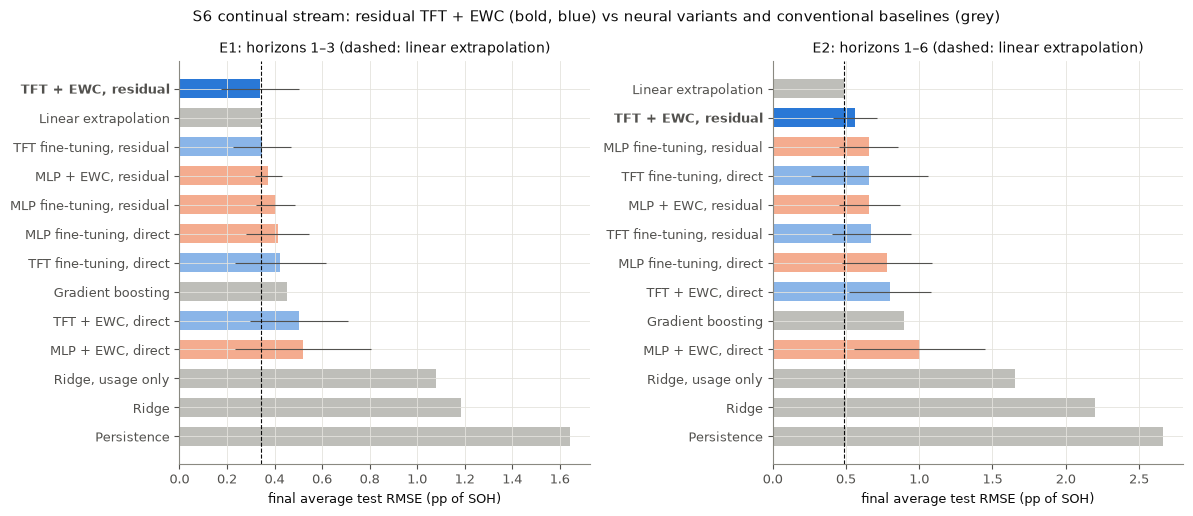

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=False)
for ax, exp in zip(axes, ("e1", "e2")):
    c = comp[exp].sort_values("rmse_main_mean", ascending=False)
    colours = ["#2a78d6" if m == REF else O.FAMILY_COLOUR.get(O.family(m), O.GREY) if O.family(m) else O.GREY
               for m in c["method"]]
    alpha = [1.0 if m == REF else 0.55 for m in c["method"]]
    bars = ax.barh(c["label"], c["rmse_main_mean"], xerr=c["rmse_main_sd"].fillna(0), color=colours,
                   height=0.65, error_kw={"elinewidth": 0.8, "ecolor": O.INK2})
    for b, a in zip(bars, alpha):
        b.set_alpha(a)
    lin = c.loc[c["method"] == "linear_extrapolation", "rmse_main_mean"].iloc[0]
    ax.axvline(lin, color=O.INK, linestyle="--", linewidth=0.8)
    ax.set_xlabel("final average test RMSE (pp of SOH)")
    ax.set_title(f"{exp.upper()}: horizons {data[exp]['horizons'][0]}–{data[exp]['horizons'][-1]} "
                 f"(dashed: linear extrapolation)")
    for lbl in ax.get_yticklabels():
        if lbl.get_text() == O.label(REF):
            lbl.set_fontweight("bold")
fig.suptitle("S6 continual stream: residual TFT + EWC (bold, blue) vs neural variants and conventional baselines (grey)")
fig.tight_layout()
plt.show()

## 4. Forgetting: what EWC adds to the residual TFT

In [6]:
rows = []
for exp in ("e1", "e2"):
    runs = pd.DataFrame(data[exp]["runs"])
    for st in ("main", "replicate"):
        r = runs[runs["set"] == st]
        for m in ("tft_residual_ewc", "tft_residual_finetune"):
            g = r[r["method"] == m]
            rows.append({"experiment": exp.upper(), "set": st, "method": O.label(m),
                         "RMSE (pp)": g["final_avg_error"].mean(), "forgetting (pp)": g["forgetting"].mean()})
display(pd.DataFrame(rows).round(3))
t = pd.concat([tests[e].assign(experiment=e.upper()) for e in ("e1", "e2")])
display(t[t["other"] == O.label("tft_residual_finetune")][["experiment", "metric", "diff_main", "p_holm_main",
                                                           "diff_replicate", "p_holm_replicate", "verdict"]].round(4))

,experiment,set,method,RMSE (pp),forgetting (pp)
0,E1,main,"TFT + EWC, residual",0.339,0.100
1,E1,main,"TFT fine-tuning, residual",0.347,0.103
2,E1,replicate,"TFT + EWC, residual",0.314,0.066
3,E1,replicate,"TFT fine-tuning, residual",0.337,0.086
4,E2,main,"TFT + EWC, residual",0.561,0.093
5,E2,main,"TFT fine-tuning, residual",0.673,0.282
6,E2,replicate,"TFT + EWC, residual",0.534,0.086
7,E2,replicate,"TFT fine-tuning, residual",0.612,0.220


,experiment,metric,diff_main,p_holm_main,diff_replicate,p_holm_replicate,verdict
18,E1,final_avg_error,-0.0080,1.0000,-0.0234,1.0000,practically equivalent
19,E1,forgetting,-0.0037,1.0000,-0.0204,1.0000,practically equivalent
20,E1,backward_transfer,-0.0049,1.0000,-0.0203,1.0000,practically equivalent
18,E2,final_avg_error,-0.1116,0.0958,-0.0783,0.1718,not replicated
19,E2,forgetting,-0.1895,0.0001,-0.1338,0.0016,"replicated, reference better"
20,E2,backward_transfer,-0.1450,0.0261,-0.1084,0.0429,"replicated, reference better"


## 5. Per test case (CLAUDE.md: per-group metrics; main seeds, test RMSE after the last stream step)

In [7]:
for exp in ("e1", "e2"):
    print(exp.upper())
    display(O.per_group(data[exp]).round(3))

E1


,case1,case2,case3,case4,case5,case6,case7,mean
"TFT + EWC, residual",0.286,0.311,0.333,0.320,0.302,0.378,0.443,0.339
"TFT fine-tuning, residual",0.281,0.308,0.352,0.310,0.294,0.424,0.461,0.347
"MLP + EWC, residual",0.300,0.368,0.356,0.367,0.370,0.417,0.441,0.374
"MLP fine-tuning, residual",0.339,0.387,0.412,0.391,0.395,0.472,0.439,0.405
"MLP fine-tuning, direct",0.360,0.299,0.549,0.324,0.382,0.450,0.526,0.413
"TFT fine-tuning, direct",0.433,0.388,0.618,0.325,0.388,0.390,0.425,0.424
"TFT + EWC, direct",0.513,0.438,0.754,0.392,0.466,0.505,0.457,0.504
"MLP + EWC, direct",0.359,0.373,0.575,0.524,0.528,0.672,0.604,0.519


E2


,case1,case2,case3,case4,case5,case6,case7,mean
"TFT + EWC, residual",0.403,0.463,0.560,0.583,0.524,0.682,0.713,0.561
"MLP fine-tuning, residual",0.484,0.530,0.661,0.707,0.675,0.886,0.648,0.656
"TFT fine-tuning, direct",0.657,0.583,0.869,0.516,0.619,0.688,0.679,0.658
"MLP + EWC, residual",0.485,0.532,0.662,0.713,0.679,0.892,0.649,0.659
"TFT fine-tuning, residual",0.563,0.611,0.638,0.657,0.576,0.891,0.772,0.673
"MLP fine-tuning, direct",0.601,0.539,1.026,0.636,0.632,0.944,1.091,0.781
"TFT + EWC, direct",0.732,0.617,1.120,0.668,0.768,0.839,0.871,0.802
"MLP + EWC, direct",0.739,0.730,1.240,1.025,1.021,1.299,0.971,1.004


## 6. Reading the results

Every number below is printed by the cells above (diff = TFT + EWC − other, main / replicate, pp; verdicts by the D21 rule).

**Against the conventional models, residual TFT + EWC is better, and every such difference replicates, except against linear extrapolation:**
- Gradient boosting: −0.112 / −0.138 (E1) and −0.337 / −0.365 (E2).
- Ridge (schedule and shared inputs) and persistence: between −0.74 and −2.13 in both experiments.
- Linear extrapolation: practically equivalent in E1 (−0.004 / −0.029). Not replicated in E2 on the final error (+0.076 / +0.049), where linear extrapolation is lower; it is replicated better at horizons 1 and 2 (+0.189 / +0.144 and +0.103 / +0.076), and the two are practically equivalent at horizons 5 and 6.

**Against the other neural continual learners:**
- Residual TFT + EWC beats the direct TFT and direct MLP variants on final error, with every difference replicated except against direct fine-tuning (MLP in E1, TFT in both).
- Against the residual MLP it is replicated better than MLP fine-tuning in E1 only. Against MLP + EWC the E1 gap is below 0.05 pp in the main set, and in E2 the main set is not significant.

**What EWC adds** (residual TFT + EWC vs residual TFT fine-tuning):
- E1: practically equivalent on every metric.
- E2: forgetting is lower, and this replicates (0.093 vs 0.282 pp in the main set, 0.086 vs 0.220 in the replicate); backward transfer also replicates. The lower final error in E2 is not replicated.

**Claim for the paper:** a TFT that learns a correction to linear extrapolation, with EWC, is the best of the learned models and clearly outperforms gradient boosting, ridge and persistence, but it does not beat simple linear extrapolation on S6. EWC's replicated benefit is reduced forgetting over the longer horizons (E2). These are results on S6 only, with SOH relative to the first RPT capacity, so they are not comparable with literature numbers obtained on other datasets or SOH definitions.